# HTC surrogate: Figure 2 and SI material

Run from the `ML training scripts and models` folder. Section 1 makes Figure 2 (cross-validated parity plots); section 2 makes Figures S2 and S3 and Tables S2 and S3 (`SI_ML_tables.xlsx`).

## 1. Figure 2

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

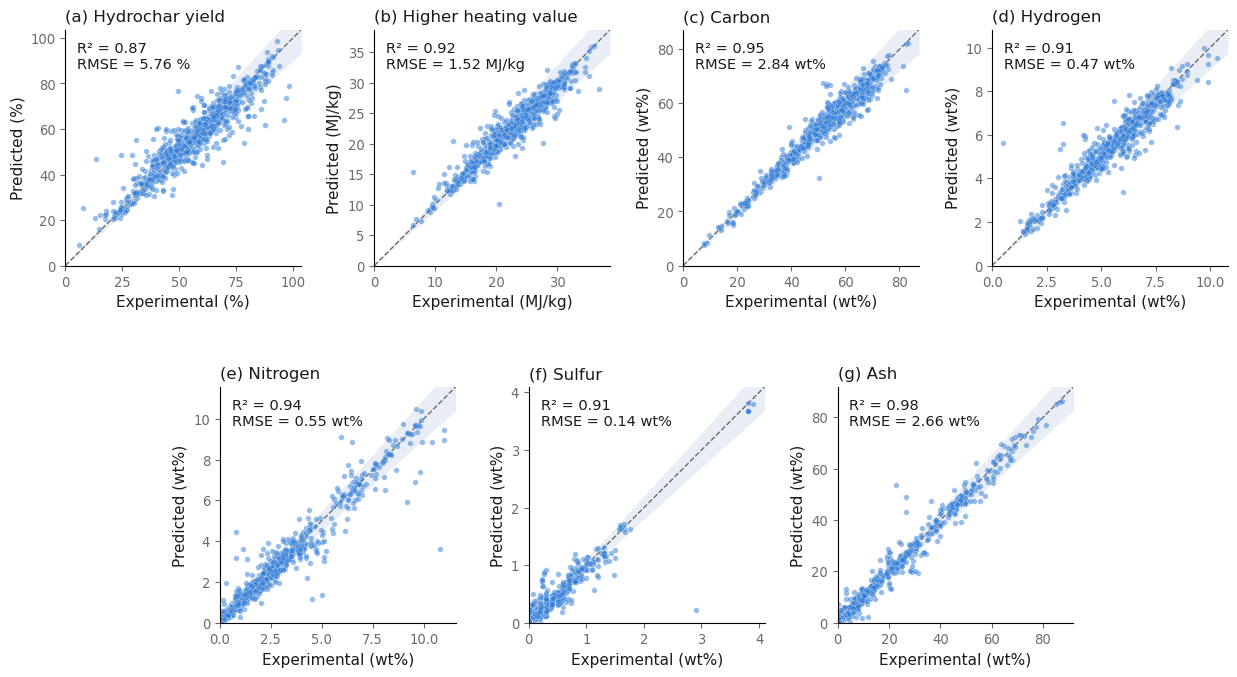

              output   n  R2_mean  R2_sd  RMSE
     Hydrochar yield 866    0.867  0.004 5.759
Higher heating value 849    0.916  0.006 1.522
              Carbon 923    0.952  0.001 2.843
            Hydrogen 923    0.909  0.002 0.468
            Nitrogen 923    0.938  0.004 0.551
              Sulfur 855    0.906  0.001 0.138
                 Ash 838    0.981  0.001 2.659


In [8]:
# =============================================================================
# Figure 2: parity plots of the HTC surrogate, random 10-fold CV
#   Out-of-fold predictions, three repeated partitions (seeds 100-102);
#   the plot shows seed 100, R2 is the mean of the three.
# =============================================================================
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error

import os
ML_DIR = os.path.join(os.getcwd() if os.path.isdir(os.path.join(os.getcwd(), "ADM1")) else os.path.dirname(os.getcwd()), "ML training scripts and models")
DATA = os.path.join(ML_DIR, "HTC_dataset_paper.xlsx")                     # training set
BEST = os.path.join(ML_DIR, "htc_xgb_best_params.json")      # tuned hyperparameters
FEATURES = ["time (min)", "temp(C)", "VM(%)", "FC(%)", "Ci(%)", "Hi(%)", "Ni(%)", "Si(%)", "Ashi", "Sv_BL"]
TARGETS = {"Bio_char(%)": ("Hydrochar yield", "%"), "HHVo(Mj/kg)": ("Higher heating value", "MJ/kg"),
           "Co(%)": ("Carbon", "wt%"), "Ho(%)": ("Hydrogen", "wt%"), "No(%)": ("Nitrogen", "wt%"),
           "So(%)": ("Sulfur", "wt%"), "Asho": ("Ash", "wt%")}
SEEDS = (100, 101, 102)

df = pd.read_excel(DATA, "data")
assert len(df) == 938, f"{len(df)} rows, expected 938"
X_all = df[FEATURES].apply(pd.to_numeric, errors="coerce")
best = {t: v["params"] for t, v in json.load(open(BEST)).items()}

plt.rcParams.update({"font.family": ["Liberation Sans", "DejaVu Sans"], "font.size": 11, "axes.linewidth": 0.8})
BLUE, INK, GREY, BAND = "#2a78d6", "#1a1a1a", "#6b6a66", "#e9eef6"
fig = plt.figure(figsize=(15, 8))
gs = GridSpec(2, 8, figure=fig, hspace=0.38, wspace=0.9)
slots = [gs[0, 0:2], gs[0, 2:4], gs[0, 4:6], gs[0, 6:8], gs[1, 1:3], gs[1, 3:5], gs[1, 5:7]]
rows = []
for k, ((t, (name, unit)), slot) in enumerate(zip(TARGETS.items(), slots)):
    ax = fig.add_subplot(slot)
    y = pd.to_numeric(df[t], errors="coerce"); m = y.notna()
    X, yy = X_all[m], y[m].values
    preds = [cross_val_predict(XGBRegressor(tree_method="hist", n_jobs=2, random_state=s, **best[t]),
                               X, yy, cv=KFold(10, shuffle=True, random_state=s)) for s in SEEDS]
    r2s = [r2_score(yy, p) for p in preds]; p = preds[0]          # plot = seed 100
    rmse = mean_squared_error(yy, p) ** 0.5
    rows.append(dict(output=name, n=len(yy), R2_mean=np.mean(r2s), R2_sd=np.std(r2s), RMSE=rmse))
    hi = max(yy.max(), p.max()) * 1.05; xs = np.array([0, hi])
    ax.fill_between(xs, xs * 0.9, xs * 1.1, color=BAND, lw=0, zorder=0)     # +/-10 % band
    ax.plot(xs, xs, ls="--", color=GREY, lw=1, zorder=1)
    ax.scatter(yy, p, s=16, color=BLUE, alpha=0.5, edgecolors="white", linewidths=0.3, zorder=2)
    ax.set_xlim(0, hi); ax.set_ylim(0, hi); ax.set_aspect("equal")
    ax.set_title(f"({'abcdefg'[k]}) {name}", loc="left", fontsize=12, color=INK, pad=6)
    ax.set_xlabel(f"Experimental ({unit})", color=INK); ax.set_ylabel(f"Predicted ({unit})", color=INK)
    ax.text(0.05, 0.95, f"R² = {np.mean(r2s):.2f}\nRMSE = {rmse:.2f} {unit}", transform=ax.transAxes,
            va="top", ha="left", fontsize=10.5, color=INK,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2))
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    ax.tick_params(colors=GREY, labelsize=9.5)
plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))

## 2. SI: SHAP importance, training domain, hyperparameters

,n,min,p1,p99,max,mean,std
Residence time (min),938,0.00,5.00,900.00,1440.00,162.03,193.28
Temperature (°C),938,100.00,140.00,300.00,300.00,217.19,35.14
VM (%),697,36.06,36.20,93.62,95.90,72.75,13.32
FC (%),691,0.00,0.68,24.30,36.50,11.57,6.12
C (%),938,19.01,21.60,54.86,80.74,43.05,7.53
H (%),938,1.64,1.64,8.27,8.90,5.86,1.29
N (%),938,0.00,0.09,10.95,13.10,2.80,2.74
S (%),876,0.00,0.00,1.73,9.50,0.35,0.80
Ash (%),938,0.00,0.16,56.50,60.90,13.39,14.06
Water/biomass ratio (-),938,1.00,1.00,23.33,50.00,8.90,5.95


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

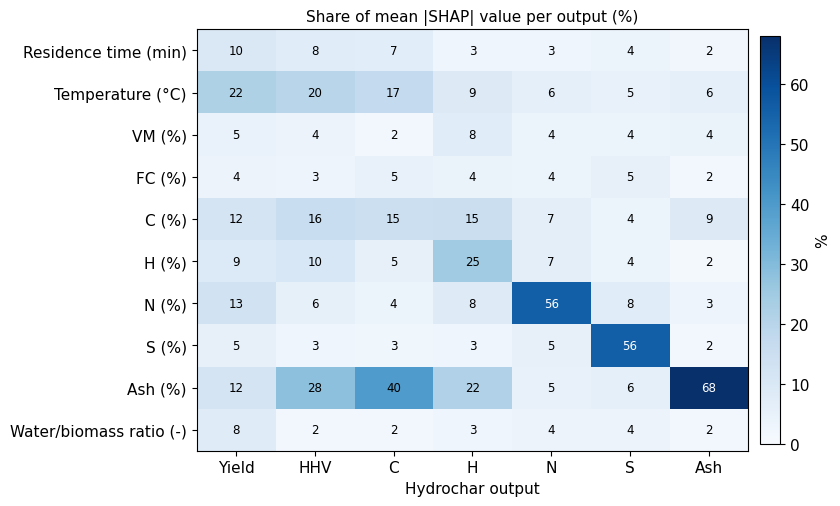

Top input per output: {'Yield': 'Temperature (°C)', 'HHV': 'Ash (%)', 'C': 'Ash (%)', 'H': 'H (%)', 'N': 'N (%)', 'S': 'S (%)', 'Ash': 'Ash (%)'}


findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

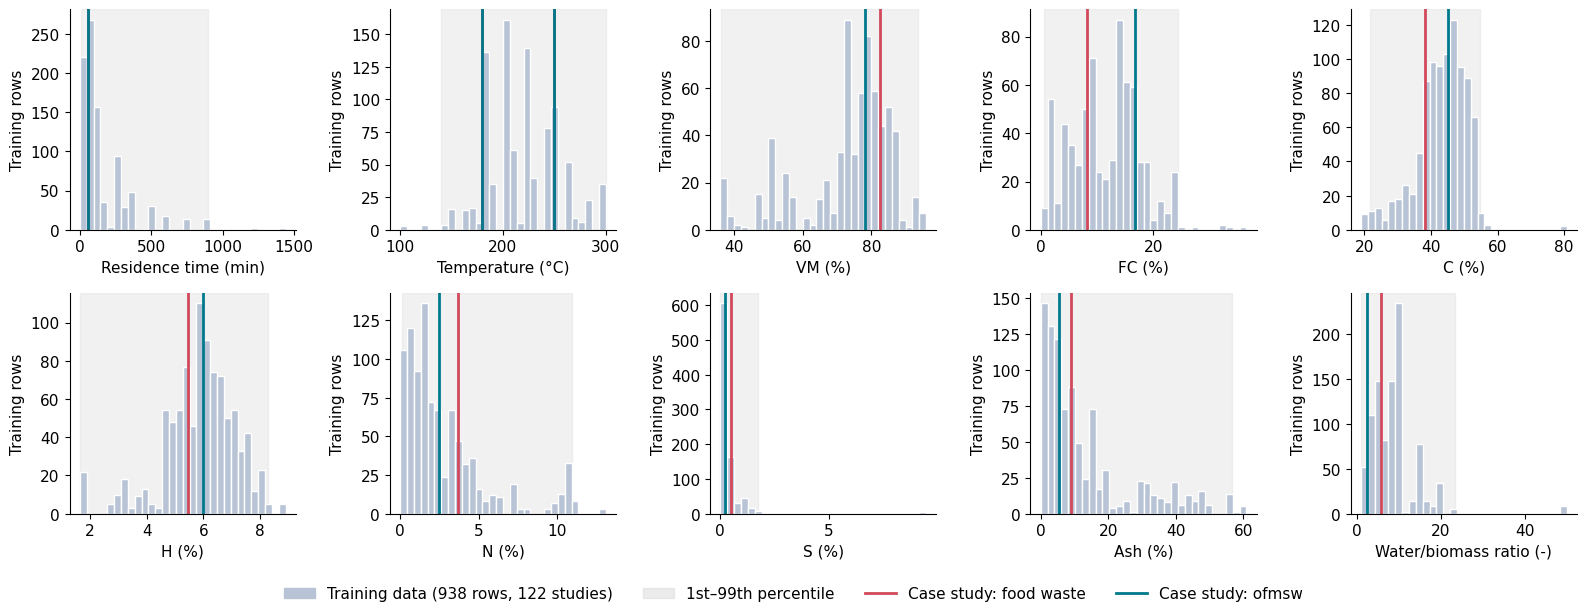

food_waste: inputs outside the 1st–99th percentile of training: none
ofmsw: inputs outside the 1st–99th percentile of training: none


,Yield,HHV,C,H,N,S,Ash
subsample,0.700,0.900,0.900,0.700,0.700,0.700,0.70
reg_lambda,1.000,1.000,3.000,10.000,3.000,1.000,1.00
reg_alpha,0.000,0.500,0.500,0.500,0.000,0.000,0.00
n_estimators,1000.000,1000.000,1000.000,600.000,600.000,600.000,1000.00
min_child_weight,1.000,7.000,7.000,1.000,3.000,7.000,1.00
max_depth,4.000,6.000,6.000,6.000,8.000,5.000,4.00
learning_rate,0.100,0.030,0.100,0.050,0.050,0.030,0.10
colsample_bytree,1.000,0.800,1.000,0.600,0.800,0.600,1.00
training rows,866.000,849.000,923.000,923.000,923.000,855.000,838.00
"R² (5-fold CV, search)",0.866,0.912,0.944,0.906,0.928,0.892,0.98


Environment: Python 3.10.12, xgboost 3.0.5, scikit-learn 1.7.2, numpy 2.2.6, pandas 2.3.3
Saved figures to figures and tables to SI_ML_tables.xlsx


In [10]:
# =============================================================================
# SI: HTC surrogate
#   Figure S3 (SHAP importance), Table S2 (training range), Figure S2 (input
#   distributions + case study inputs), Table S3 (hyperparameters, CV R2)
# =============================================================================
import os, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xgboost as xgb

ROOT = os.getcwd() if os.path.isdir(os.path.join(os.getcwd(), "ADM1")) else os.path.dirname(os.getcwd())   # repository root
MLD = os.path.join(ROOT, "ML training scripts and models")
OUT = os.path.join(ROOT, "figures"); os.makedirs(OUT, exist_ok=True)
META = json.load(open(os.path.join(MLD, "htc_xgb_models", "metadata.json")))
df = pd.read_excel(os.path.join(MLD, "HTC_dataset_paper.xlsx"), "data")
F, TGT = META["features"], list(META["targets"])
assert len(df) == META["n_rows"], f"dataset has {len(df)} rows, model metadata says {META['n_rows']}"
X = df[F].apply(pd.to_numeric, errors="coerce")

FLAB = {"time (min)": "Residence time (min)", "temp(C)": "Temperature (°C)", "VM(%)": "VM (%)",
        "FC(%)": "FC (%)", "Ci(%)": "C (%)", "Hi(%)": "H (%)", "Ni(%)": "N (%)", "Si(%)": "S (%)",
        "Ashi": "Ash (%)", "Sv_BL": "Water/biomass ratio (-)"}
TLAB = {"Bio_char(%)": "Yield", "HHVo(Mj/kg)": "HHV", "Co(%)": "C", "Ho(%)": "H",
        "No(%)": "N", "So(%)": "S", "Asho": "Ash"}

# ---------------------------------------------------------------- Table S2: training range
s2 = pd.DataFrame({"n": X.notna().sum(), "min": X.min(), "p1": X.quantile(.01), "p99": X.quantile(.99),
                   "max": X.max(), "mean": X.mean(), "std": X.std()})
s2.index = [FLAB[c] for c in s2.index]
# QA: ranges match those stored with the model (used by the applicability check)
for c in F:
    lo, hi = META["feature_range"][c]
    assert np.isclose(X[c].min(), lo) and np.isclose(X[c].max(), hi), f"range of {c} differs from metadata"
display(s2.round(2))

# ---------------------------------------------------------------- Figure S3: SHAP (TreeSHAP, built into XGBoost)
imp = {}
for t, m in META["targets"].items():
    b = xgb.Booster(); b.load_model(os.path.join(MLD, "htc_xgb_models", m["file"]))
    y = pd.to_numeric(df[t], errors="coerce"); msk = y.notna()
    dm = xgb.DMatrix(X[msk], missing=np.nan)
    contrib = b.predict(dm, pred_contribs=True)          # last column = expected value
    pred = b.predict(dm)
    gap = np.abs(contrib.sum(axis=1) - pred).max()
    assert gap < 1e-3 * max(1.0, np.abs(pred).max()), f"SHAP additivity fails for {t} (max gap {gap:.3g})"
    assert msk.sum() == m["n_train"], f"{t}: {msk.sum()} rows vs {m['n_train']} at training"
    mabs = np.abs(contrib[:, :-1]).mean(axis=0)
    imp[TLAB[t]] = 100 * mabs / mabs.sum()               # share of total mean |SHAP|, %
imp = pd.DataFrame(imp, index=[FLAB[c] for c in F])

fig, ax = plt.subplots(figsize=(8.5, 5.2))
im = ax.imshow(imp.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(imp.shape[1])); ax.set_xticklabels(imp.columns)
ax.set_yticks(range(imp.shape[0])); ax.set_yticklabels(imp.index)
for i in range(imp.shape[0]):
    for j in range(imp.shape[1]):
        v = imp.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.6 * imp.values.max() else "black")
ax.set_xlabel("Hydrochar output"); ax.set_title("Share of mean |SHAP| value per output (%)", fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="%")
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(OUT, f"FigureS3_SHAP_importance.{ext}"), dpi=300, bbox_inches="tight")
plt.show()
print("Top input per output:", {t: imp[t].idxmax() for t in imp.columns})

# ---------------------------------------------------------------- Figure S2: input distributions + case study inputs
# case study feedstocks (as in case_study.ipynb, section 2)
FEEDS_ = {
    "food_waste": dict(C_feed=38.25, H_feed=5.47, N_feed=3.66, S_feed=0.50, Ash_feed=9.10,
                       VM_feed=82.6, FC_feed=8.3, WC=85.0),
    "ofmsw":      dict(C_feed=45.00, H_feed=6.00, N_feed=2.50, S_feed=0.20, Ash_feed=5.30,
                       VM_feed=78.0, FC_feed=16.7, WC=70.0),
}
cases = {}
if FEEDS_:
    MAPF = {"VM(%)": "VM_feed", "FC(%)": "FC_feed", "Ci(%)": "C_feed", "Hi(%)": "H_feed",
            "Ni(%)": "N_feed", "Si(%)": "S_feed", "Ashi": "Ash_feed"}
    for name, f in FEEDS_.items():
        v = {c: f[k] for c, k in MAPF.items()}
        v["Sv_BL"] = f["WC"] / (100 - f["WC"])
        v["time (min)"] = 60
        v["temp(C)"] = [180, 250]
        cases[name] = v
CCOL = {"food_waste": "#d1495b", "ofmsw": "#00798c"}

fig, axes = plt.subplots(2, 5, figsize=(16, 6.2))
for ax, c in zip(axes.ravel(), F):
    v = X[c].dropna()
    ax.hist(v, bins=30, color="#b8c4d6", edgecolor="white")
    ax.axvspan(v.quantile(.01), v.quantile(.99), color="0.85", alpha=0.35, zorder=0)
    for name, d in cases.items():
        for xv in np.atleast_1d(d[c]):
            ax.axvline(xv, color=CCOL.get(name, "black"), lw=2)
    ax.set_xlabel(FLAB[c]); ax.set_ylabel("Training rows")
    ax.spines[["top", "right"]].set_visible(False)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
h = [Patch(color="#b8c4d6", label="Training data (938 rows, 122 studies)"),
     Patch(color="0.85", alpha=0.5, label="1st–99th percentile")]
h += [Line2D([], [], color=CCOL.get(n, "black"), lw=2, label=f"Case study: {n.replace('_', ' ')}") for n in cases]
fig.legend(handles=h, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=[0, 0.06, 1, 1])
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(OUT, f"FigureS2_training_domain.{ext}"), dpi=300, bbox_inches="tight")
plt.show()
for name, d in cases.items():                            # QA: where the case study sits
    out = [FLAB[c] for c in F for xv in np.atleast_1d(d[c])
           if not X[c].quantile(.01) <= xv <= X[c].quantile(.99)]
    print(f"{name}: inputs outside the 1st–99th percentile of training: {out or 'none'}")

# ---------------------------------------------------------------- Table S3: hyperparameters and CV R2
s3 = pd.DataFrame({TLAB[t]: {**m["params"], "training rows": m["n_train"],
                             "R² (5-fold CV, search)": round(m["search_R2_5fold"], 3)}
                   for t, m in META["targets"].items()})
display(s3)
print("Environment:", META["environment"])

with pd.ExcelWriter(os.path.join(ROOT, "results", "SI_ML_tables.xlsx")) as w:
    s2.round(3).to_excel(w, sheet_name="Table S2 training range")
    s3.to_excel(w, sheet_name="Table S3 hyperparameters")
    imp.round(2).to_excel(w, sheet_name="Figure S3 data")
print("Saved figures to", OUT, "and tables to SI_ML_tables.xlsx")